# Week 2: streamflow in a future climate (Gsteig)

Present = the WeaGETS ensemble (order 2 + Gamma, 50 realizations of 30 years).
Future = the same ensemble with the delta changes of Table 1 (5 climate models x 2 RCPs, 2070-2099).
The Bucket Model uses the Exercise 2 parameters (NSE calibration), as in `tutorial.ipynb`.

Daily runoff is summarized per realization (mean monthly runoff, annual maximum daily runoff) and cached in
`data/week2_<STATION>_<WEAGETS>.pkl`; delete that file to rerun the model (about 7 minutes).
The same cached run also gives the mean annual runoff used for the uncertainty partition (Task 3).
Figures are saved to `images/week2/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from data_processing import process_mat_file
from paths import DATA_DIR, IMAGES_DIR
import week2_streamflow as w2

STATION = "GSTEIG"
WEAGETS = "O2_D2"  # Markov order 2 + Gamma
simulation_path = DATA_DIR / f"{STATION}_{WEAGETS}_OUT.mat"
future_dir = DATA_DIR / f"Future{STATION.capitalize()}_{WEAGETS}"
FIG_DIR = IMAGES_DIR / "week2"
FIG_DIR.mkdir(exist_ok=True)

results = w2.run_all(
    present_simulated=process_mat_file(simulation_path),
    future_dir=future_dir,
    cache=DATA_DIR / f"week2_{STATION}_{WEAGETS}.pkl",
)
results["annual_max"].groupby(["group", "climate_model"]).size()

group    climate_model       
Present  -                       50
RCP4.5   CLMCOM-CCLM4-ECEARTH    50
         CLMCOM-CCLM4-HADGEM     50
         DMI-HIRHAM-ECEARTH      50
         MPICSC-REMO1-MPIESM     50
         SMHI-RCA-IPSL           50
RCP8.5   CLMCOM-CCLM4-ECEARTH    50
         CLMCOM-CCLM4-HADGEM     50
         DMI-HIRHAM-ECEARTH      50
         MPICSC-REMO1-MPIESM     50
         SMHI-RCA-IPSL           50
dtype: int64

## (a) Seasonality: mean monthly runoff

Boxes: the 5 climate models of each RCP (5 values; each = mean over that model's 50 realizations and 30 years), so the box
width shows the climate model spread. Line: the present ensemble mean.

Jan   Feb    Mar    Apr    May    Jun    Jul  \
group   climate_model                                                          
Present -                      33.2  18.9   21.0   43.9  116.8  241.0  314.9   
RCP4.5  CLMCOM-CCLM4-ECEARTH   57.1  39.3   47.4   85.4  175.2  268.9  239.8   
        CLMCOM-CCLM4-HADGEM    71.4  53.9   67.2  112.2  194.2  228.6  183.9   
        DMI-HIRHAM-ECEARTH     49.9  33.2   39.5   73.6  159.5  262.2  246.4   
        MPICSC-REMO1-MPIESM    53.3  36.0   43.2   79.2  166.9  265.0  241.6   
        SMHI-RCA-IPSL          66.2  49.8   62.1  104.7  182.8  212.5  168.8   
RCP8.5  CLMCOM-CCLM4-ECEARTH   85.3  68.0   86.0  134.9  200.3  206.7  173.5   
        CLMCOM-CCLM4-HADGEM   103.9  89.8  113.8  152.1  168.3  163.7  155.9   
        DMI-HIRHAM-ECEARTH     75.8  59.0   74.4  120.4  191.9  206.1  167.9   
        MPICSC-REMO1-MPIESM    73.1  57.6   72.9  117.1  179.5  183.9  150.9   
        SMHI-RCA-IPSL          90.2  78.4   99.4  129.9  137.1  132.9  126.9   

                                Aug    Sep    Oct    Nov    Dec  
group   climate_model                                            
Present -                     243.8  162.6  125.4   87.2   56.8  
RCP4.5  CLMCOM-CCLM4-ECEARTH  174.3  142.5  126.7  100.6   80.7  
        CLMCOM-CCLM4-HADGEM   152.1  134.5  124.0  103.1   91.0  
        DMI-HIRHAM-ECEARTH    173.6  137.6  120.7   94.2   73.0  
        MPICSC-REMO1-MPIESM   172.8  139.2  123.1   97.0   76.5  
        SMHI-RCA-IPSL         139.6  123.9  114.6   95.5   84.3  
RCP8.5  CLMCOM-CCLM4-ECEARTH  154.0  139.6  130.0  110.2  102.3  
        CLMCOM-CCLM4-HADGEM   147.8  137.0  129.3  112.9  113.1  
        DMI-HIRHAM-ECEARTH    145.2  130.6  121.5  102.4   93.1  
        MPICSC-REMO1-MPIESM   132.6  120.4  112.7   95.7   88.2  
        SMHI-RCA-IPSL         120.6  112.5  107.5   94.8   96.4

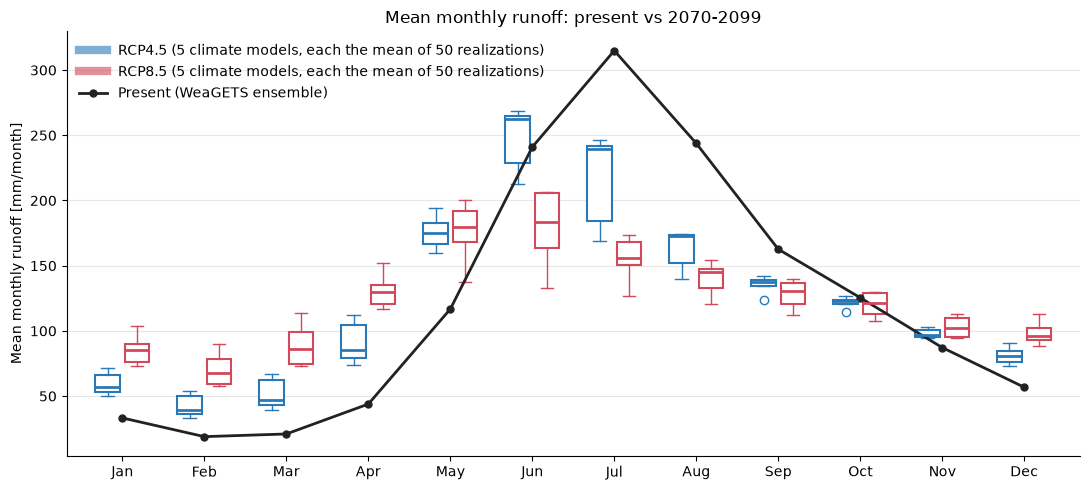

In [2]:
monthly_table = w2.plot_monthly_boxplot(
    results["monthly"], output_destination=FIG_DIR / f"{STATION}_{WEAGETS}_monthly_runoff_boxplot.png"
)
monthly_table

### (a') Same, as bands over all realizations

For each 30-year realization the mean monthly runoff is computed. Line = median, band = 5-95% over the
realizations: present 50, each RCP 5 climate models x 50 realizations. The future bands therefore contain
both the climate model spread and the natural (stochastic) variability; the present band is natural
variability only (the boxplot above shows the climate model spread only).

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
"(Present, 5%)",27.7,15.1,16.7,36.3,107.0,224.9,296.1,222.9,150.1,117.2,79.6,48.5
"(Present, median)",32.9,18.5,20.7,43.1,114.5,241.7,313.6,241.2,162.1,125.1,87.5,57.3
"(Present, 95%)",39.1,24.5,26.9,53.7,129.1,256.3,334.0,270.2,175.3,134.4,94.8,63.2
"(RCP4.5, 5%)",46.0,29.9,35.4,68.8,153.8,204.0,160.3,134.7,119.5,109.7,87.6,67.2
"(RCP4.5, median)",58.6,40.8,48.9,87.0,175.2,254.5,227.2,165.0,136.4,121.9,97.8,80.6
"(RCP4.5, 95%)",74.9,57.8,73.2,117.2,200.1,281.4,264.3,188.0,148.7,132.8,108.4,95.8
"(RCP8.5, 5%)",68.7,52.2,66.6,109.8,131.1,127.5,121.8,115.7,108.4,103.6,89.5,82.9
"(RCP8.5, median)",84.4,67.9,86.8,128.5,179.7,181.7,156.7,141.6,129.1,119.9,102.8,97.2
"(RCP8.5, 95%)",107.7,93.7,119.2,155.6,207.4,222.9,180.1,162.7,146.1,137.2,118.0,118.1


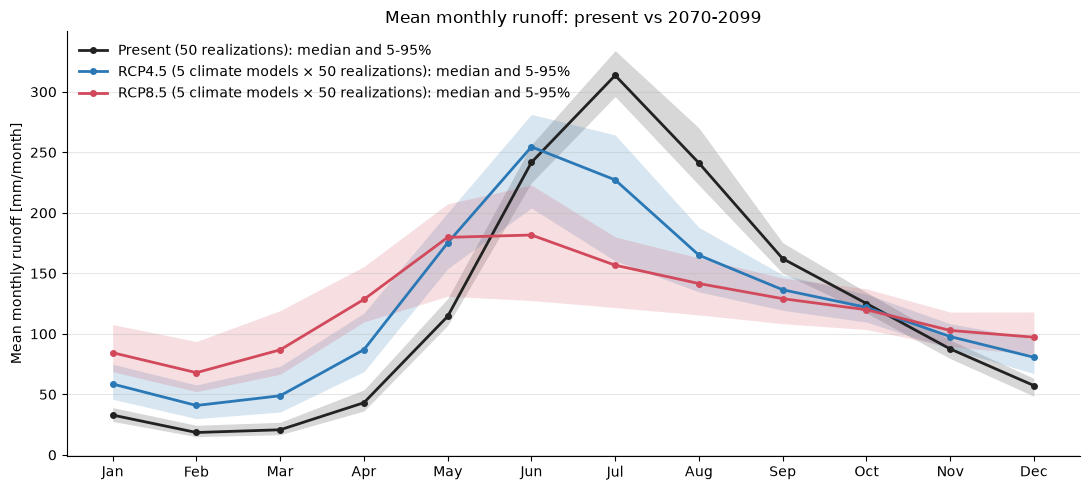

In [3]:
monthly_band_table = w2.plot_monthly_band(
    results["monthly"], output_destination=FIG_DIR / f"{STATION}_{WEAGETS}_monthly_runoff_band.png"
)
monthly_band_table

## Extremes: return period of the annual maximum daily runoff

Empirical return periods only (no distribution fitted). In each 30-year realization the annual maxima are
sorted and the Weibull plotting position T = (n+1)/rank (n = 30) is assigned, so every realization gives
points at T = 31, 15.5, 10.3, ..., 1.03 years. Line = median over the realizations at each rank,
band = 5-95%. Present: 50 realizations; each RCP: 5 climate models x 50 realizations.

Median [mm/d]  \
Group                                       T [years]                  
Present (50 realizations)                   2.1                 15.4   
                                            5.2                 17.8   
                                            10.3                18.8   
                                            31.0                21.1   
RCP4.5 (5 climate models × 50 realizations) 2.1                 13.8   
                                            5.2                 16.1   
                                            10.3                17.5   
                                            31.0                20.2   
RCP8.5 (5 climate models × 50 realizations) 2.1                 12.3   
                                            5.2                 14.5   
                                            10.3                16.1   
                                            31.0                18.4   

                                                      5-95% [mm/d]  \
Group                                       T [years]                
Present (50 realizations)                   2.1          14.5-16.2   
                                            5.2          16.3-19.0   
                                            10.3         17.6-21.3   
                                            31.0         18.7-25.3   
RCP4.5 (5 climate models × 50 realizations) 2.1          12.0-15.1   
                                            5.2          14.1-17.9   
                                            10.3         15.4-19.9   
                                            31.0         17.0-24.5   
RCP8.5 (5 climate models × 50 realizations) 2.1          10.4-13.6   
                                            5.2          12.2-16.4   
                                            10.3         13.4-18.4   
                                            31.0         15.1-23.8   

                                                       Change vs present [%]  
Group                                       T [years]                         
Present (50 realizations)                   2.1                          0.0  
                                            5.2                          0.0  
                                            10.3                         0.0  
                                            31.0                         0.0  
RCP4.5 (5 climate models × 50 realizations) 2.1                        -10.3  
                                            5.2                         -9.3  
                                            10.3                        -6.9  
                                            31.0                        -4.1  
RCP8.5 (5 climate models × 50 realizations) 2.1                        -19.7  
                                            5.2                        -18.3  
                                            10.3                       -14.6  
                                            31.0                       -13.0

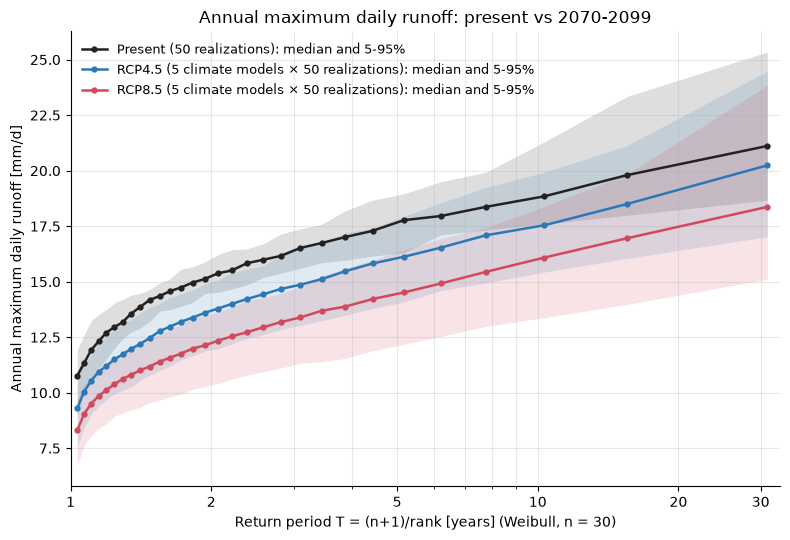

In [4]:
return_period_table = w2.plot_return_periods(
    results["annual_max"],
    output_destination=FIG_DIR / f"{STATION}_{WEAGETS}_return_periods.png",
)
return_period_table

### Mean annual maximum per climate model (for the discussion)

In [5]:
results["annual_max"].mean(axis=1).groupby(["group", "climate_model"]).describe(percentiles=[0.05, 0.5, 0.95])[
    ["5%", "50%", "95%"]
].round(1)

5%   50%   95%
group   climate_model                         
Present -                     14.6  15.4  16.1
RCP4.5  CLMCOM-CCLM4-ECEARTH  13.7  14.5  15.5
        CLMCOM-CCLM4-HADGEM   12.8  13.4  14.4
        DMI-HIRHAM-ECEARTH    13.4  14.2  15.1
        MPICSC-REMO1-MPIESM   13.5  14.3  15.3
        SMHI-RCA-IPSL         12.0  12.5  13.4
RCP8.5  CLMCOM-CCLM4-ECEARTH  12.8  13.4  14.3
        CLMCOM-CCLM4-HADGEM   12.3  12.8  13.5
        DMI-HIRHAM-ECEARTH    12.3  12.8  13.7
        MPICSC-REMO1-MPIESM   11.4  11.9  12.7
        SMHI-RCA-IPSL         10.4  10.9  11.4

## Task 3: partition of the uncertainty of the mean annual runoff

Same method as `tutorial.ipynb` (`UncertaintyAnalysis`), using the mean annual runoff of each of the
2 RCPs x 5 climate models x 50 realizations from the cached run above (no extra model run):
- Total (TU): 5-95% range of all 2 x 5 x 50 realizations
- Emission scenario (EU): |median RCP8.5 - median RCP4.5|
- Climate model (CMU): max - min of the 5 model means, averaged over the 2 RCPs
- Stochastic (SU): 5-95% range of the realizations of the median climate model, averaged over the 2 RCPs

Partition = each uncertainty / TU (the partitions do not have to add up to 1).

In [6]:
uncertainty_table = w2.uncertainty_partition(results["annual_mean"])
uncertainty_table

,Uncertainty [mm/yr],Partition [-]
Total (TU),283.95,1.00
Emission scenario (EU),4.90,0.02
Climate model (CMU),198.68,0.70
Stochastic (SU),85.61,0.30


In [7]:
# Mean annual runoff [mm/yr] per climate model and RCP (median and 5-95% over the realizations)
results["annual_mean"].groupby(["group", "climate_model"]).describe(percentiles=[0.05, 0.5, 0.95])[
    ["5%", "50%", "95%"]
].round(0)

5%     50%     95%
group   climate_model                               
Present -                     1428.0  1463.0  1510.0
RCP4.5  CLMCOM-CCLM4-ECEARTH  1496.0  1535.0  1585.0
        CLMCOM-CCLM4-HADGEM   1476.0  1512.0  1563.0
        DMI-HIRHAM-ECEARTH    1424.0  1461.0  1508.0
        MPICSC-REMO1-MPIESM   1454.0  1491.0  1539.0
        SMHI-RCA-IPSL         1367.0  1401.0  1448.0
RCP8.5  CLMCOM-CCLM4-ECEARTH  1548.0  1587.0  1639.0
        CLMCOM-CCLM4-HADGEM   1544.0  1583.0  1635.0
        DMI-HIRHAM-ECEARTH    1448.0  1484.0  1534.0
        MPICSC-REMO1-MPIESM   1347.0  1381.0  1427.0
        SMHI-RCA-IPSL         1290.0  1323.0  1367.0